# UbiLife Dataset Exploration

This notebook explores the UbiLife mobile sensing dataset collected during UbiComp 2025 in Helsinki, Finland (~82 participants, Oct 9-29 2025).

**Goals**: Understand what data we have, its shape, coverage, and quality — to inform the data preparation pipeline.

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from carp import CarpDataStream

# ── Project paths ──
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"
PARQUET_DIR = PROJECT_ROOT / "data" / "processed"
PARQUET_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ── Plot style ──
sns.set_theme(style="whitegrid", palette="husl")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

# ── Visualisation imports ──
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from visualisation import (
    plot_stream_overview, plot_daily_volume, plot_participant_spans,
    plot_records_per_participant, plot_step_cumulative_vs_delta,
    plot_activity_types, plot_devices, plot_survey_overview,
    plot_demographics, plot_daily_surveys, plot_who5_bfi10,
    plot_session_ratings, plot_weather,
)

# ── Data stream ──
stream = CarpDataStream(str(DATA_DIR / "data-streams.json"))

# Convert JSON → Parquet (only runs if parquet files don't exist yet)
if not any(PARQUET_DIR.glob("*.parquet")):
    stream.convert_to_parquet(PARQUET_DIR)


def load_stream(name):
    """Load a parquet file and extract timestamp + participant ID."""
    df = stream.get_dataframe(name, parquet_dir=PARQUET_DIR)
    df["timestamp"] = pd.to_datetime(df["measurement.sensorStartTime"], unit="us", errors="coerce")
    df["participant_id"] = df["dataStream.studyDeploymentId"]
    return df

print(f"Parquet dir: {PARQUET_DIR}")
print(f"Available streams: {sorted(f.stem for f in PARQUET_DIR.glob('*.parquet'))}")

In [ ]:
# Show available fields in measurement.data for ALL streams
# With json_normalize, nested fields become dot-separated columns.

all_streams = sorted(f.stem for f in PARQUET_DIR.glob("*.parquet"))

for name in all_streams:
    df_raw = pd.read_parquet(PARQUET_DIR / f"{name}.parquet")

    # Extract measurement.data.* column names (excluding __type)
    prefix = "measurement.data."
    data_cols = sorted(
        c[len(prefix):] for c in df_raw.columns
        if c.startswith(prefix) and not c.endswith(".__type")
    )
    keys_str = ", ".join(data_cols) if data_cols else "(no fields)"
    print(f"{name:25s} ({len(df_raw):>7,} records)  →  {keys_str}")

## 1. Dataset Overview — Record Counts & Participant Coverage per Stream

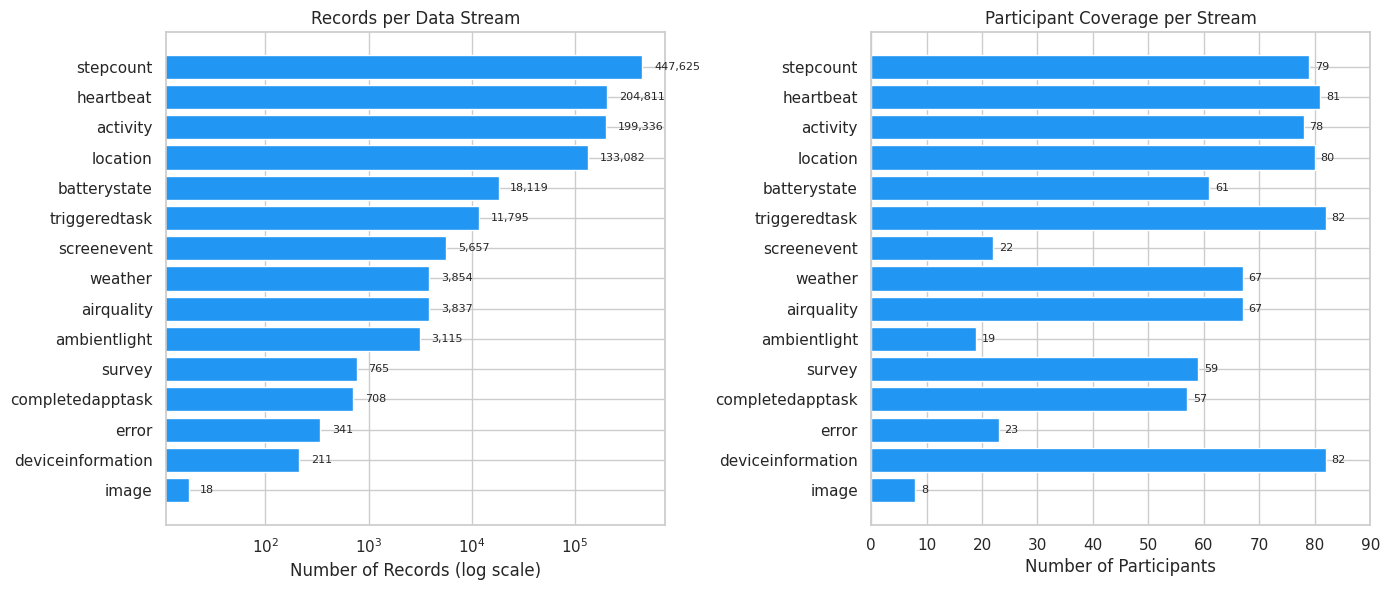


Total records across all streams: 1,033,274
Total unique participants: 82


In [38]:
stream_names = sorted(f.stem for f in PARQUET_DIR.glob("*.parquet"))

overview = []
stream_participant_ids = {}

for name in stream_names:
    df_tmp = pd.read_parquet(PARQUET_DIR / f"{name}.parquet")
    ids = df_tmp["dataStream.studyDeploymentId"]
    stream_participant_ids[name] = set(ids.dropna())
    overview.append({"stream": name, "records": len(df_tmp), "participants": ids.nunique()})

overview_df = pd.DataFrame(overview).sort_values("records", ascending=True)

plot_stream_overview(overview_df, FIGURES_DIR)

print(f"\nTotal records across all streams: {overview_df['records'].sum():,}")
print(f"Total unique participants: {len(set.union(*stream_participant_ids.values()))}")

## 2. Temporal Coverage — When Was Data Collected?

Understanding the active collection window and per-participant gaps.

In [ ]:
# Load key streams for temporal analysis
df_steps = load_stream("stepcount")
df_loc = load_stream("location")
df_activity = load_stream("activity")
df_survey = load_stream("survey")

plot_daily_volume(
    {"stepcount": df_steps, "location": df_loc,
     "activity": df_activity, "survey": df_survey},
    FIGURES_DIR,
)

In [ ]:
participant_spans = (
    df_steps.groupby("participant_id")["timestamp"]
    .agg(["min", "max", "count"])
    .sort_values("min")
)
participant_spans["days_active"] = (participant_spans["max"] - participant_spans["min"]).dt.days + 1

plot_participant_spans(participant_spans, FIGURES_DIR)

print(f"Active days: median={participant_spans['days_active'].median():.0f}, "
      f"mean={participant_spans['days_active'].mean():.1f}, "
      f"range={participant_spans['days_active'].min()}-{participant_spans['days_active'].max()}")
print(f"\nHow to read this chart:")
print(f"  - Each horizontal bar is one participant")
print(f"  - Bar starts at their first step record, ends at their last")
print(f"  - Green = many records (reliable data), Red = few records (sparse data)")
print(f"  - Blue shaded area = main conference week (Oct 13-17)")
print(f"  - Most participants started around conference start; a few kept collecting after")

## 3. Records per Participant — Distribution & Outliers

In [ ]:
plot_records_per_participant(
    {"stepcount": df_steps, "location": df_loc,
     "activity": df_activity, "survey": df_survey},
    FIGURES_DIR,
)

## 4. Sensor Data Samples — What Do the Actual Values Look Like?

In [ ]:
# Pick one participant with decent data
top_step_pid = df_steps.groupby("participant_id").size().idxmax()
one_p = df_steps[df_steps["participant_id"] == top_step_pid].sort_values("timestamp").copy()
one_p["steps"] = one_p["measurement.data.steps"]
one_p["step_delta"] = one_p["steps"].diff().clip(lower=0)

plot_step_cumulative_vs_delta(one_p, FIGURES_DIR)

In [ ]:
df_activity["activity_type"] = df_activity["measurement.data.type"]

plot_activity_types(df_activity, FIGURES_DIR)

## 5. Device & Platform Breakdown

In [ ]:
df_device = load_stream("deviceinformation")
df_device["platform"] = df_device["measurement.data.platform"]
df_device["manufacturer"] = df_device["measurement.data.deviceManufacturer"]
df_device["hardware"] = df_device["measurement.data.hardware"].fillna("")

plot_devices(df_device, FIGURES_DIR)

pid_platform = df_device.groupby("participant_id")["platform"].first().value_counts()
print("Unique participants per platform:")
for p, c in pid_platform.items():
    print(f"  {p}: {c}")

## 6. Survey Deep Dive

In [ ]:
# Parse survey metadata — flat columns from json_normalize
df_survey["status"] = df_survey["measurement.data.status"]
df_survey["survey_type"] = df_survey["measurement.data.result.identifier"].fillna("unknown")

submitted = df_survey[df_survey["status"] == "submitted"]
canceled = df_survey[df_survey["status"] == "canceled"]

plot_survey_overview(df_survey, submitted, FIGURES_DIR)

print(f"Total surveys: {len(df_survey)} (submitted: {len(submitted)}, canceled: {len(canceled)})")
print(f"Participants with submitted survey: {submitted['participant_id'].nunique()}")
print(f"Completion rate: {len(submitted)/len(df_survey)*100:.1f}%")

In [ ]:
# --- Parse survey answers from flat parquet columns ---
# json_normalize creates columns like:
#   measurement.data.result.results.{step_id}.results.answer
# We find all such columns and extract the step_id from the column name.

import re

ANSWER_COL_PATTERN = re.compile(
    r"^measurement\.data\.result\.results\.(.+?)\.results\.answer$"
)

# Build mapping: column_name -> step_id
answer_columns = {}
for col in submitted.columns:
    m = ANSWER_COL_PATTERN.match(col)
    if m:
        answer_columns[col] = m.group(1)

print(f"Found {len(answer_columns)} answer columns across all survey types")


def extract_answer(answer):
    """Extract (value, text) from an answer field, regardless of format."""
    if answer is None or (isinstance(answer, float) and np.isnan(answer)):
        return None, None

    # numpy array of RPChoice dicts (most common after parquet)
    if isinstance(answer, np.ndarray):
        answer = answer.tolist()

    # List of RPChoice dicts: [{"text": "Male", "value": 1}, ...]
    if isinstance(answer, list) and len(answer) > 0 and isinstance(answer[0], dict):
        if len(answer) == 1:
            return answer[0].get("value"), answer[0].get("text")
        else:
            return ([c.get("value") for c in answer],
                    [c.get("text") for c in answer])

    # String that looks like a Python list of dicts (raw JSON edge case)
    if isinstance(answer, str) and answer.startswith("[{"):
        try:
            import ast
            parsed = ast.literal_eval(answer)
            if isinstance(parsed, list) and len(parsed) > 0:
                if len(parsed) == 1:
                    return parsed[0].get("value"), parsed[0].get("text")
                return ([c.get("value") for c in parsed],
                        [c.get("text") for c in parsed])
        except (ValueError, SyntaxError):
            pass

    # Scalar (float, int, plain string)
    return answer, str(answer)


def parse_survey_answers_flat(row):
    """Extract clean {step_id: (value, text)} from flat parquet columns."""
    survey_id = row.get("survey_type", "unknown")
    answers = {}

    for col, step_id in answer_columns.items():
        raw_answer = row.get(col)
        if raw_answer is None:
            continue
        if isinstance(raw_answer, float) and np.isnan(raw_answer):
            continue

        value, text = extract_answer(raw_answer)
        if value is not None:
            answers[step_id] = {"value": value, "text": text}

    return {"survey_type": survey_id, "answers": answers}


# Parse all submitted surveys
parsed = submitted.apply(parse_survey_answers_flat, axis=1, result_type="expand")
submitted_parsed = pd.concat(
    [submitted[["participant_id", "timestamp"]].reset_index(drop=True), parsed], axis=1
)

# Quick sanity check
print(f"Parsed {len(submitted_parsed)} submitted surveys")
sample = submitted_parsed[submitted_parsed["survey_type"] == "onboarding.task"].iloc[0]["answers"]
for k, v in sample.items():
    print(f"  {k}: value={v['value']!r}  text={v['text']!r}")

In [ ]:
onboarding = submitted_parsed[submitted_parsed["survey_type"] == "onboarding.task"]

ages, genders, roles, prior = [], [], [], []
for _, row in onboarding.iterrows():
    a = row["answers"]
    if "onboarding.age.step" in a:
        try:
            ages.append(float(a["onboarding.age.step"]["value"]))
        except (ValueError, TypeError):
            pass
    if "onboarding.gender.step" in a:
        genders.append(str(a["onboarding.gender.step"]["text"]))
    if "onboarding.academic.step" in a:
        txt = str(a["onboarding.academic.step"]["text"])
        txt = txt.replace("Student (PhD, MSc, BSc)", "Student").replace("Researcher", "Researcher")
        roles.append(txt)
    if "onboarding.prior.step" in a:
        txt = str(a["onboarding.prior.step"]["text"])
        txt = (txt.replace("This is my first UbiComp", "First")
               .replace(" UbiComp conferences", "")
               .replace(" UbiComp conference", ""))
        prior.append(txt)

plot_demographics(ages, genders, roles, prior, FIGURES_DIR)

In [ ]:
stress_vals, sleep_quality_texts, sleep_hour_texts = [], [], []

for _, row in submitted_parsed.iterrows():
    st = row["survey_type"]
    if not isinstance(st, str):
        continue
    a = row["answers"]
    if st == "daily.stress.task" and "daily.stress.step" in a:
        try:
            stress_vals.append(float(a["daily.stress.step"]["value"]))
        except (ValueError, TypeError):
            pass
    if st == "daily.sleep.task":
        if "daily.sleep.step" in a:
            sleep_quality_texts.append(str(a["daily.sleep.step"]["text"]))
        if "daily.sleep.hours.step" in a:
            sleep_hour_texts.append(str(a["daily.sleep.hours.step"]["text"]))

plot_daily_surveys(stress_vals, sleep_quality_texts, sleep_hour_texts, FIGURES_DIR)

In [ ]:
who5_rows = submitted_parsed[submitted_parsed["survey_type"] == "who5.task"]
who5_scores = []
for _, row in who5_rows.iterrows():
    vals = []
    for q in range(1, 6):
        key = f"survey.who5.question.{q}"
        if key in row["answers"]:
            try:
                vals.append(int(row["answers"][key]["value"]))
            except (ValueError, TypeError):
                pass
    if len(vals) == 5:
        who5_scores.append({"participant_id": row["participant_id"],
                            "raw_sum": sum(vals), "pct_score": sum(vals) * 4})

bfi_rows = submitted_parsed[submitted_parsed["survey_type"] == "bfi10.task"]
bfi_dimensions = []
for _, row in bfi_rows.iterrows():
    items = {}
    for q in range(1, 11):
        key = f"bfi10.question{q}"
        if key in row["answers"]:
            try:
                items[q] = int(row["answers"][key]["value"])
            except (ValueError, TypeError):
                pass
    if len(items) == 10:
        bfi_dimensions.append({
            "participant_id": row["participant_id"],
            "Extraversion": (4 - items[1] + items[6]) / 2,
            "Agreeableness": (items[2] + 4 - items[7]) / 2,
            "Conscientiousness": (4 - items[3] + items[8]) / 2,
            "Neuroticism": (4 - items[4] + items[9]) / 2,
            "Openness": (4 - items[5] + items[10]) / 2,
        })

plot_who5_bfi10(who5_scores, bfi_dimensions, FIGURES_DIR)

if who5_scores:
    who5_df = pd.DataFrame(who5_scores)
    print(f"WHO-5: n={len(who5_df)}, median={who5_df['pct_score'].median():.0f}%, "
          f"below 50%: {(who5_df['pct_score'] < 50).sum()}")
if bfi_dimensions:
    bfi_df = pd.DataFrame(bfi_dimensions)
    dims = ["Extraversion", "Agreeableness", "Conscientiousness", "Neuroticism", "Openness"]
    print(f"\nBFI-10 dimension means (n={len(bfi_df)}):")
    for d in dims:
        print(f"  {d:20s}: mean={bfi_df[d].mean():.2f}, std={bfi_df[d].std():.2f}")

In [ ]:
session_ratings = []
for _, row in submitted_parsed.iterrows():
    st = row["survey_type"]
    if not isinstance(st, str):
        continue
    a = row["answers"]
    if st.startswith("survey.session.") and st.endswith(".task"):
        letter = st.replace("survey.session.", "").replace(".task", "")
        key = f"survey.session.rating.question.{letter}.step"
        if key in a:
            session_ratings.append({"session": f"Session {letter}", "rating": str(a[key]["text"])})
    elif st.startswith("survey.keynote.") and st.endswith(".task"):
        num = st.replace("survey.keynote.", "").replace(".task", "")
        key = f"survey.keynote.{num}.step"
        if key in a:
            session_ratings.append({"session": f"Keynote {num}", "rating": str(a[key]["text"])})

plot_session_ratings(session_ratings, FIGURES_DIR)

## 7. Weather & Environment

In [ ]:
df_weather = load_stream("weather")
df_weather["temperature"] = df_weather["measurement.data.temperature"]
df_weather["humidity"] = df_weather["measurement.data.humidity"]
df_weather["weather_main"] = df_weather["measurement.data.weatherMain"]
df_weather["wind_speed"] = df_weather["measurement.data.windSpeed"]

plot_weather(df_weather, FIGURES_DIR)

## 8. Key Findings & Data Preparation Implications

**Dataset structure:**
- 15 data streams, 1M+ records, 82 participants, Oct 9-29 2025
- Data flattened via `json_normalize` into dot-separated columns (e.g. `measurement.data.steps`)
- `participant-data.json` has no PII; participants identified only by `studyDeploymentId`
- Timestamps in microseconds (`sensorStartTime`, unit="us")

**Data quality issues for preparation:**
- Step counts are **cumulative** — must compute deltas (and handle resets/negatives)
- Survey answers may be stored as lists of dicts after parquet round-trip — need type-aware parsing
- Large variance in records/participant — some have 30k+ steps records, others <10
- Screen events only available for 22/82 participants (mostly Android?)

**Usable cohort:**
- 56 participants have survey + steps + location (best for multimodal analysis)
- 57 completed onboarding; 38 completed WHO-5; 48 completed BFI-10
- Daily surveys (stress/sleep) have ~73-81 responses across the study

**For data preparation notebook:**
1. **Filter to conference week (Oct 13-16)** — discard sensor data outside the main conference dates to focus analysis on the event itself
2. **Convert cumulative step counts to deltas** — and handle resets/negatives
3. **Parse survey answers into structured tables** — one clean DataFrame per survey type (e.g. onboarding: one row per participant with `age`, `gender`, `role` columns; daily stress: one row per participant per day)
4. **Define "usable participant" criteria** — minimum streams + survey completion
5. **Create unified participant feature table** — one row per participant, all derived features as columns (demographics, BFI-10 dimensions, WHO-5, activity metrics, etc.) — this feeds directly into correlation, clustering, and predictive model notebooks